In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

In [18]:
df = pd.read_csv("healthcare_dataset.csv")

print("Dataset Loaded Successfully")
display(df.head())

display(df.tail())

print("Shape:", df.shape)

Dataset Loaded Successfully


,Patient_ID,Age,Gender,Blood_Pressure,Heart_Rate,Cholesterol_Level,BMI,Diagnosis,Treatment_Plan,Follow_Up_Date
0,1,51,Female,97,90,282,35.2,Hypertension,Observation,2024-01-01
1,2,92,Other,129,80,169,32.3,Healthy,Medication,2024-01-02
2,3,14,Male,172,76,157,29.9,Diabetes,Observation,2024-01-03
3,4,71,Female,131,82,150,19.4,Coronary Artery Disease,Surgery,2024-01-04
4,5,60,Male,130,96,206,39.3,Diabetes,NaN,2024-01-05


,Patient_ID,Age,Gender,Blood_Pressure,Heart_Rate,Cholesterol_Level,BMI,Diagnosis,Treatment_Plan,Follow_Up_Date
495,496,62,Other,151,88,222,27.6,Healthy,Medication,2025-05-10
496,497,68,Other,169,69,198,27.3,Healthy,Lifestyle Changes,2025-05-11
497,498,21,Female,177,71,185,38.0,Hypertension,Observation,2025-05-12
498,499,92,Female,172,89,275,33.9,Hypertension,Medication,2025-05-13
499,500,66,Other,97,60,217,31.6,Diabetes,NaN,2025-05-14


Shape: (500, 10)


In [19]:
df.info()

print(df.columns)
print(df.select_dtypes(include=np.number).columns)
print(df.select_dtypes(include="object").columns)

display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         500 non-null    int64  
 1   Age                500 non-null    int64  
 2   Gender             500 non-null    object 
 3   Blood_Pressure     500 non-null    int64  
 4   Heart_Rate         500 non-null    int64  
 5   Cholesterol_Level  500 non-null    int64  
 6   BMI                500 non-null    float64
 7   Diagnosis          500 non-null    object 
 8   Treatment_Plan     405 non-null    object 
 9   Follow_Up_Date     500 non-null    object 
dtypes: float64(1), int64(5), object(4)
memory usage: 39.2+ KB
Index(['Patient_ID', 'Age', 'Gender', 'Blood_Pressure', 'Heart_Rate',
       'Cholesterol_Level', 'BMI', 'Diagnosis', 'Treatment_Plan',
       'Follow_Up_Date'],
      dtype='object')
Index(['Patient_ID', 'Age', 'Blood_Pressure', 'Heart_Rate',
       'Chol

,Patient_ID,Age,Blood_Pressure,Heart_Rate,Cholesterol_Level,BMI
count,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,48.87400,133.024000,79.874000,225.806000,29.430400
std,144.481833,29.56983,25.665246,11.354293,44.964608,6.132838
min,1.000000,0.00000,90.000000,60.000000,150.000000,18.600000
25%,125.750000,23.00000,112.000000,70.750000,186.000000,24.100000
50%,250.500000,50.00000,132.000000,79.500000,226.000000,29.600000
75%,375.250000,72.25000,154.000000,90.000000,267.000000,34.725000
max,500.000000,99.00000,179.000000,99.000000,299.000000,40.000000


In [5]:
print(df.isnull().sum())
print((df.isnull().sum() / len(df)) * 100)
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

display(missing_report)

Patient_ID            0
Age                   0
Gender                0
Blood_Pressure        0
Heart_Rate            0
Cholesterol_Level     0
BMI                   0
Diagnosis             0
Treatment_Plan       95
Follow_Up_Date        0
dtype: int64
Patient_ID            0.0
Age                   0.0
Gender                0.0
Blood_Pressure        0.0
Heart_Rate            0.0
Cholesterol_Level     0.0
BMI                   0.0
Diagnosis             0.0
Treatment_Plan       19.0
Follow_Up_Date        0.0
dtype: float64


,Missing_Count,Percentage
Patient_ID,0,0.0
Age,0,0.0
Gender,0,0.0
Blood_Pressure,0,0.0
Heart_Rate,0,0.0
Cholesterol_Level,0,0.0
BMI,0,0.0
Diagnosis,0,0.0
Treatment_Plan,95,19.0
Follow_Up_Date,0,0.0


In [6]:
df = df.copy()
for col in ["Gender", "Diagnosis", "Treatment_Plan"]:
    df[col] = df[col].astype("string").str.strip()

df["Treatment_Plan"] = df["Treatment_Plan"].fillna("Not Recorded")
print(df.isnull().sum())

Patient_ID           0
Age                  0
Gender               0
Blood_Pressure       0
Heart_Rate           0
Cholesterol_Level    0
BMI                  0
Diagnosis            0
Treatment_Plan       0
Follow_Up_Date       0
dtype: int64


In [7]:
print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

print("Age zero values:", (df["Age"] == 0).sum())

print("Gender:", df["Gender"].unique())
print("Diagnosis:", df["Diagnosis"].unique())
print("Treatment:", df["Treatment_Plan"].unique())

Duplicates: 0
Age zero values: 9
Gender: <StringArray>
['Female', 'Other', 'Male']
Length: 3, dtype: string
Diagnosis: <StringArray>
[           'Hypertension',                 'Healthy',
                'Diabetes', 'Coronary Artery Disease',
          'Hyperlipidemia']
Length: 5, dtype: string
Treatment: <StringArray>
['Observation', 'Medication', 'Surgery', 'Not Recorded', 'Lifestyle Changes']
Length: 5, dtype: string


In [8]:
display(df.describe())

,Patient_ID,Age,Blood_Pressure,Heart_Rate,Cholesterol_Level,BMI
count,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,48.87400,133.024000,79.874000,225.806000,29.430400
std,144.481833,29.56983,25.665246,11.354293,44.964608,6.132838
min,1.000000,0.00000,90.000000,60.000000,150.000000,18.600000
25%,125.750000,23.00000,112.000000,70.750000,186.000000,24.100000
50%,250.500000,50.00000,132.000000,79.500000,226.000000,29.600000
75%,375.250000,72.25000,154.000000,90.000000,267.000000,34.725000
max,500.000000,99.00000,179.000000,99.000000,299.000000,40.000000


In [9]:
print(df["Diagnosis"].value_counts())

Diagnosis
Healthy                    104
Hypertension               101
Coronary Artery Disease    101
Hyperlipidemia             101
Diabetes                    93
Name: count, dtype: Int64


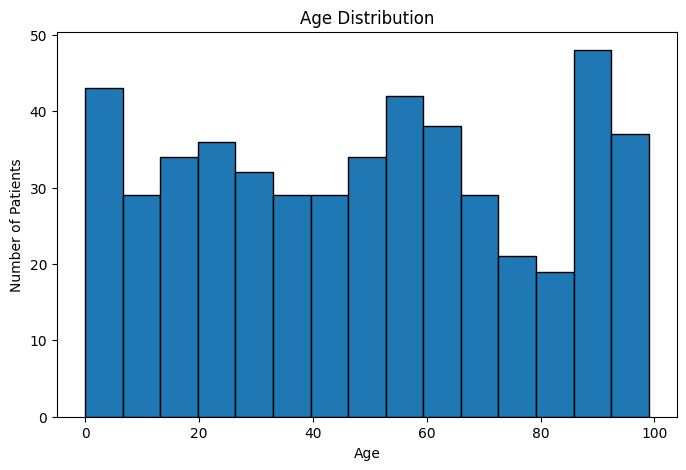

In [10]:
plt.figure(figsize=(8,5))

plt.hist(df["Age"], bins=15, edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

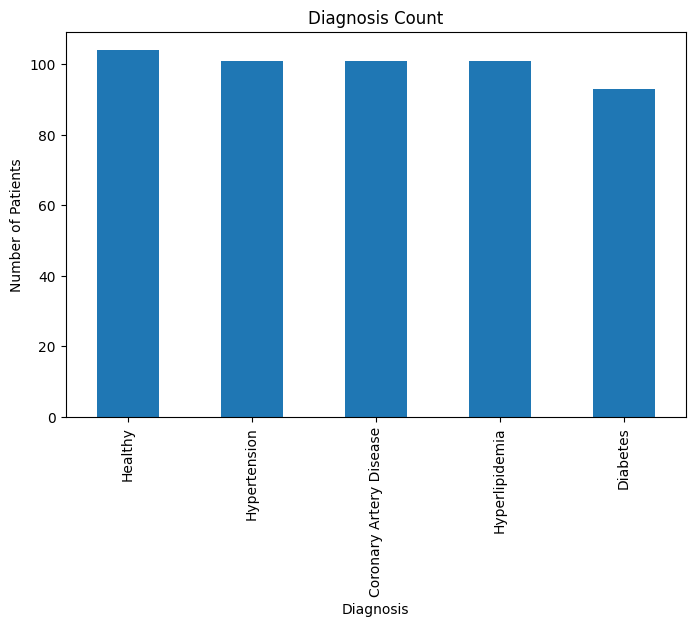

In [11]:
plt.figure(figsize=(8,5))

df["Diagnosis"].value_counts().plot(kind="bar")

plt.title("Diagnosis Count")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")

plt.show()

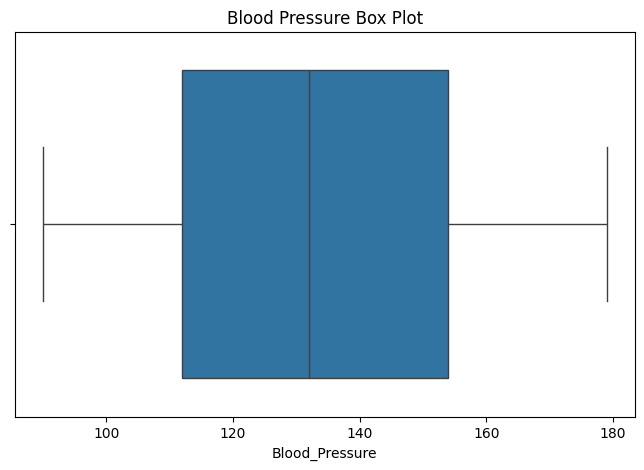

In [12]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Blood_Pressure"])

plt.title("Blood Pressure Box Plot")

plt.show()

In [13]:
df["Follow_Up_Date"] = pd.to_datetime(
    df["Follow_Up_Date"], errors="coerce"
)

df["Follow_Up_Year"] = df["Follow_Up_Date"].dt.year
df["Follow_Up_Month"] = df["Follow_Up_Date"].dt.month
df["Follow_Up_Day"] = df["Follow_Up_Date"].dt.day

df = df.drop(columns=["Follow_Up_Date"])

df = pd.get_dummies(
    df,
    columns=["Gender", "Diagnosis", "Treatment_Plan"],
    dtype=int
)

display(df.head())

print("New Shape:", df.shape)

,Patient_ID,Age,Blood_Pressure,Heart_Rate,Cholesterol_Level,BMI,Follow_Up_Year,Follow_Up_Month,Follow_Up_Day,Gender_Female,...,Diagnosis_Coronary Artery Disease,Diagnosis_Diabetes,Diagnosis_Healthy,Diagnosis_Hyperlipidemia,Diagnosis_Hypertension,Treatment_Plan_Lifestyle Changes,Treatment_Plan_Medication,Treatment_Plan_Not Recorded,Treatment_Plan_Observation,Treatment_Plan_Surgery
0,1,51,97,90,282,35.2,2024,1,1,1,...,0,0,0,0,1,0,0,0,1,0
1,2,92,129,80,169,32.3,2024,1,2,0,...,0,0,1,0,0,0,1,0,0,0
2,3,14,172,76,157,29.9,2024,1,3,0,...,0,1,0,0,0,0,0,0,1,0
3,4,71,131,82,150,19.4,2024,1,4,1,...,1,0,0,0,0,0,0,0,0,1
4,5,60,130,96,206,39.3,2024,1,5,0,...,0,1,0,0,0,0,0,1,0,0


New Shape: (500, 22)


In [14]:
columns = [
    "Age",
    "Blood_Pressure",
    "Heart_Rate",
    "Cholesterol_Level",
    "BMI"
]

scaler = StandardScaler()

df[columns] = scaler.fit_transform(df[columns])

display(df.head())

,Patient_ID,Age,Blood_Pressure,Heart_Rate,Cholesterol_Level,BMI,Follow_Up_Year,Follow_Up_Month,Follow_Up_Day,Gender_Female,...,Diagnosis_Coronary Artery Disease,Diagnosis_Diabetes,Diagnosis_Healthy,Diagnosis_Hyperlipidemia,Diagnosis_Hypertension,Treatment_Plan_Lifestyle Changes,Treatment_Plan_Medication,Treatment_Plan_Not Recorded,Treatment_Plan_Observation,Treatment_Plan_Surgery
0,1,0.071970,-1.405016,0.892714,1.250990,0.941714,2024,1,1,1,...,0,0,0,0,1,0,0,0,1,0
1,2,1.459907,-0.156945,0.011108,-1.264614,0.468376,2024,1,2,0,...,0,0,1,0,0,0,1,0,0,0
2,3,-1.180559,1.520150,-0.341534,-1.531758,0.076648,2024,1,3,0,...,0,1,0,0,0,0,0,0,1,0
3,4,0.749012,-0.078940,0.187429,-1.687592,-1.637161,2024,1,4,1,...,1,0,0,0,0,0,0,0,0,1
4,5,0.376639,-0.117943,1.421678,-0.440921,1.610916,2024,1,5,0,...,0,1,0,0,0,0,0,1,0,0


In [15]:
print("Final Shape:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

print("Duplicates:", df.duplicated().sum())

df.to_csv("healthcare_prepared.csv", index=False)

print("Dataset Saved Successfully!")

Final Shape: (500, 22)
Missing Values: 0
Duplicates: 0
Dataset Saved Successfully!
